# ARIMA — Checkpoint (week 4)

Maak per dataset een ARIMA-analyse met grid search naar optimale (p,d,q)-parameters.

## BELANGRIJK: gebruik exact de genoemde variabelennamen
De checks (`checks/test_week04.py`) voeren dit notebook uit en controleren volgende
variabelen. Gebruik exact deze namen, anders falen de checks:

- Oefening 1 (TF_BIRTHS): `series_births`, `births_2022_daily`, `monthly_births`,
  `best_order_births`, `rmse_births`
- Oefening 2 (AQI Duitsland): `aqi_germany`, `aqi_filtered`, `best_order_aqi`, `rmse_aqi`
- Oefening 3 (Electric Production): `series_electric`, `best_order_electric`, `rmse_electric`
- Meerkeuze: `antwoord_adf`, `antwoord_seizoen_births` (waarde "A", "B", "C" of "D")

Conventies die de checks gebruiken: alle grid searches met `p_values = [0, 1, 2, 4]`,
`d_values = [0, 1]`, `q_values = [0, 1]` en een 66/34 train/test-split
(`train_size = int(len(X) * 0.66)`) zoals in de gegeven helperfuncties.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from math import sqrt
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

def evaluate_arima_model(X, arima_order):
    """Walk-forward validatie: RMSE van een ARIMA(order) op reeks X (66/34-split)."""
    X = np.asarray(X, dtype="float32").ravel()
    train_size = int(len(X) * 0.66)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=arima_order)
        model_fit = model.fit()
        predictions.append(model_fit.forecast()[0])
        history.append(test[t])
    return sqrt(mean_squared_error(test, predictions))

def grid_search_arima(X, p_values, d_values, q_values):
    """Zoekt beste (p,d,q) via walk-forward RMSE. Geeft (best_order, best_rmse)."""
    best_score, best_cfg = float("inf"), None
    for p in p_values:
        for d in d_values:
            for q in q_values:
                try:
                    rmse = evaluate_arima_model(X, (p, d, q))
                except Exception:
                    continue
                if rmse < best_score:
                    best_score, best_cfg = rmse, (p, d, q)
    return best_cfg, best_score

p_values = [0, 1, 2, 4]
d_values = [0, 1]
q_values = [0, 1]


## Oefening 1 — TF_BIRTHS (geboortecijfers België)

1. Laad `./data/TF_BIRTHS.csv` in (scheidingsteken `;`) en hernoem de kolom
   `MS_NUM_BIRTHS` naar `value`. Parse de eerste kolom (`DT_DATE`, formaat
   `%d/%m/%Y`) als index. Sla op in **`series_births`** (DataFrame).
2. Maak **`births_2022_daily`**: enkel de dagcijfers van 2022. Maak een plot en
   bekijk het histogram van de dagcijfers — wat valt op? Hoe komt dat ?
3. Maak **`monthly_births`**: de volledige reeks hersamplet naar maanden (som).
   Welk seizoenspatroon zie je? (beantwoord de meerkeuzevraag verderop)
4. Test met de ADF-test of de maandreeks stationair is.
5. Zoek met grid search de beste ARIMA-parameters voor de maandreeks en sla op in
   **`best_order_births`** (tuple) en de bijhorende walk-forward RMSE in
   **`rmse_births`**.
6. Fit het finale model en plot de residuals.


            value
DT_DATE          
1992-01-01    219
1992-01-02    331
1992-01-03    420
1992-01-04    282
1992-01-05    252


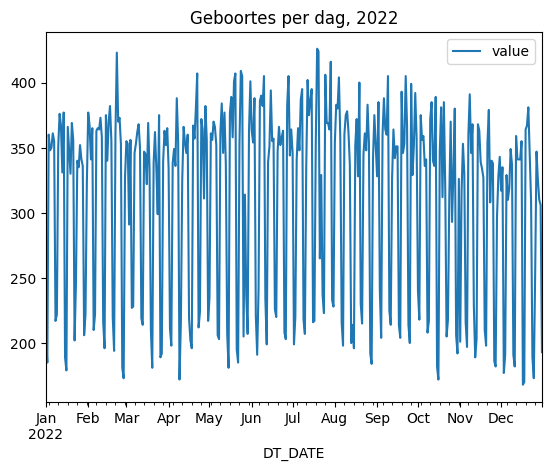

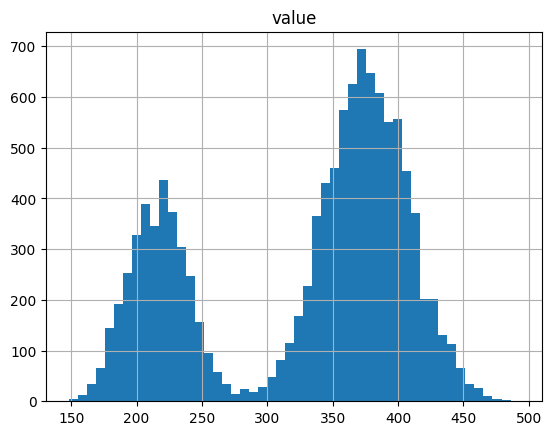

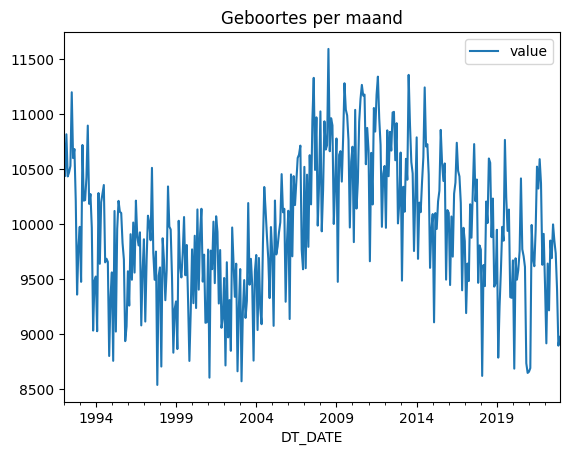

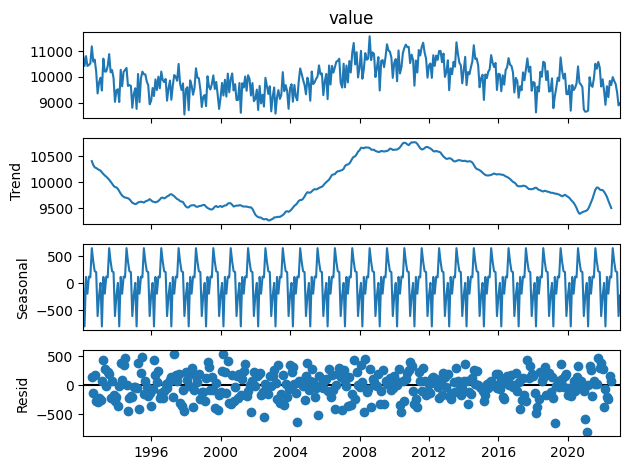

ADF statistiek: -1.219986
p-waarde: 0.664940


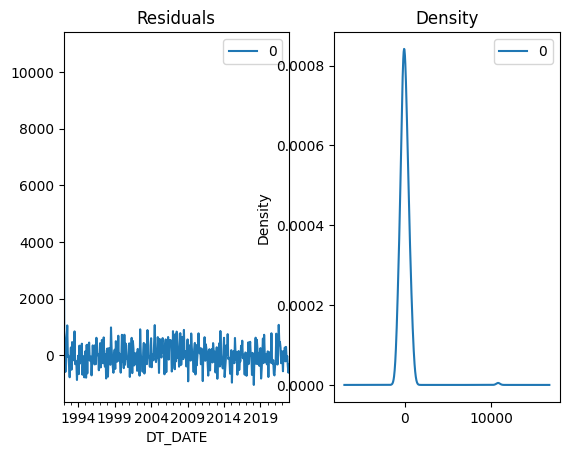

In [9]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)

# Stap 1
series_births = pd.read_csv('./data/TF_BIRTHS.csv', sep=';', index_col='DT_DATE', parse_dates=['DT_DATE'], date_format='%d/%m/%Y')
series_births = series_births.rename(columns={'MS_NUM_BIRTHS': 'value'})
print(series_births.head())

# Stap 2
births_2022_daily = series_births.loc['2022-01-01':'2022-12-31']
births_2022_daily.plot(title='Geboortes per dag, 2022')
plt.show()
series_births.hist(bins=50)
plt.show()
# Het valt op dat het histogram 2 bulten of anders 2 gemiddeldes vertoont. Bij geboortes kan dit te wijten zijn aan het feit dat er in het weekend minder kinderen geboren worden dan in de week omdat er minder keizersnedes in het weekend gebeuren. Daarom zijn er 2 gemiddeldes waarond de dagwaarden schommelen.

# Stap 3
monthly_births = series_births.resample('ME').sum()
monthly_births.plot(title='Geboortes per maand')
plt.show()

from statsmodels.tsa.seasonal import seasonal_decompose
seasonal_decompose(monthly_births['value'], model='additive').plot()
plt.show()
# Meerkeuzevraag is verder in de notebook beantwoord.

# Stap 4
result = adfuller(monthly_births.value.dropna()) #The null hypothese van de ADF test is dat de time series niet-stationair is.
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# De p-waarde is groter dan 0.05. Dit geeft aan dat de reeks niet stationair is en er differencing nodig is.

# Stap 5
best_order_births, rmse_births = grid_search_arima(monthly_births.value.dropna(), p_values, d_values, q_values)

# Stap 6
model = ARIMA(monthly_births.value.dropna(), order=best_order_births)
model_fit = model.fit()
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()


## Oefening 2 — AQI: luchtkwaliteit Duitsland

1. Laad `./data/data_date.csv` in (eerste kolom = datum-index).
2. Filter op `Country == 'Germany'` en hou enkel de kolom `AQI Value` (hernoemd naar
   `value`). Sla op in **`aqi_germany`**.
3. Filter de data tussen 21 juli 2022 en 22 september 2022 → **`aqi_filtered`**.
4. Test met de ADF-test of de reeks stationair is (beantwoord daarna de
   meerkeuzevraag `antwoord_adf`).
5. Grid search → **`best_order_aqi`** en **`rmse_aqi`**. Fit het finale model en
   plot de residuals.


ADF statistiek: -4.119410
p-waarde: 0.000899


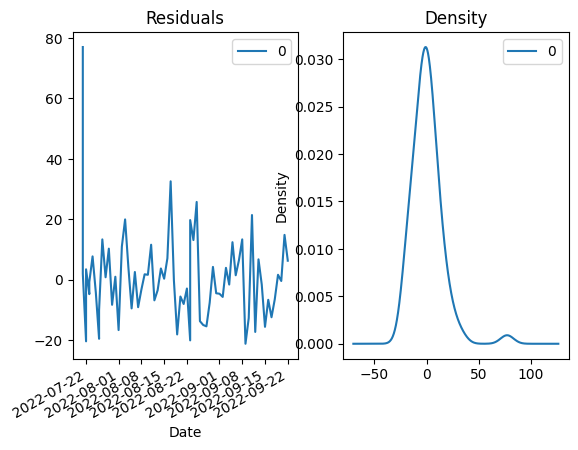

In [12]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)

# Stap 1
aqi = pd.read_csv('./data/data_date.csv', sep=',', index_col='Date', parse_dates=['Date'], date_format='%Y-%m-%d')

# Stap 2
aqi_germany = aqi[aqi['Country'] == 'Germany'][['AQI Value']]
aqi_germany = aqi_germany.rename(columns={'AQI Value':'value'})

# Stap 3
aqi_filtered = aqi_germany.loc['2022-07-21':'2022-09-22']

# Stap 4
result = adfuller(aqi_filtered.value.dropna()) #The null hypothese van de ADF test is dat de time series niet-stationair is.
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# De p-waarde is kleiner dan 0.05. Dit geeft aan dat de reeks stationair is en er geen differencing nodig is.

# Stap 5
best_order_aqi, rmse_aqi = grid_search_arima(aqi_filtered.value.dropna(), p_values, d_values, q_values)
model = ARIMA(aqi_filtered.value.dropna(), order=best_order_aqi)
model_fit = model.fit()
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()



## Oefening 3 — Electric Production

1. Laad `./data/Electric_Production.xls` in (het is effectief een CSV; eerste kolom =
   datum-index) en hernoem `Value` naar `value` → **`series_electric`**.
2. Bekijk de reeks: hier is duidelijk een trend én een seizoenspatroon, dus `d = 1`
   is een goede keuze voor de differencing.
3. Grid search → **`best_order_electric`** en **`rmse_electric`**. Fit het finale
   model en plot walk-forward voorspellingen tegen de testset.


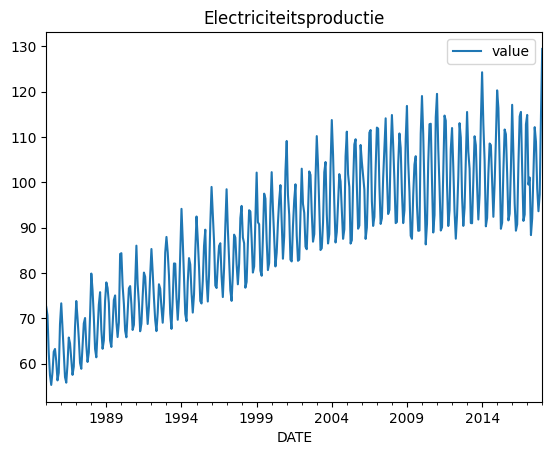

ADF statistiek: -2.256990
p-waarde: 0.186215


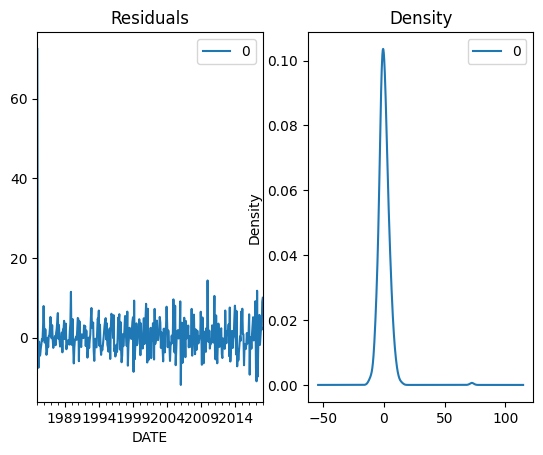

Test RMSE walk-forward: 4.399


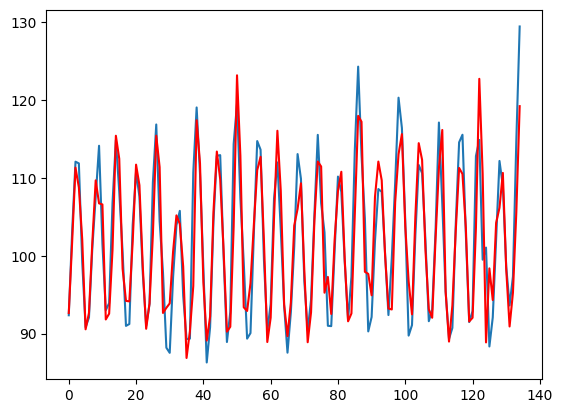

In [17]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)

# Stap 1
series_electric = pd.read_csv('./data/Electric_Production.xls', sep=',', index_col='DATE', parse_dates=['DATE'])
series_electric = series_electric.rename(columns={'Value':'value'})

# Stap 2
series_electric.plot(title='Electriciteitsproductie')
plt.show()
result = adfuller(series_electric.value.dropna()) #The null hypothese van de ADF test is dat de time series niet-stationair is.
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# De p-waarde is groter dan 0.05. Dit geeft aan dat de reeks niet stationair is en er differencing nodig is.

# Stap 3
best_order_electric, rmse_electric = grid_search_arima(series_electric.value.dropna(), p_values, d_values, q_values)
model = ARIMA(series_electric.value.dropna(), order=best_order_electric)
model_fit = model.fit()
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()

X_electric = series_electric['value'].values.astype('float32').ravel()
size = int(len(X_electric) * 0.66)
train_electric, test_electric = X_electric[0:size], X_electric[size:]
history = [x for x in train_electric]
predictions = list()
for t in range(len(test_electric)):
    model = ARIMA(history, order=best_order_electric)
    model_fit = model.fit()
    predictions.append(model_fit.forecast()[0])
    history.append(test_electric[t])

rmse_wf = sqrt(mean_squared_error(test_electric, predictions))
print('Test RMSE walk-forward: %.3f' % rmse_wf)

plt.plot(test_electric)
plt.plot(predictions, color='red')
plt.show()




## Meerkeuzevragen

**Vraag 1 (ADF):** de p-waarde van de ADF-test op de gefilterde AQI-reeks van Duitsland
is kleiner dan 0.05. Wat betekent dit?

- A) De reeks is niet-stationair; er is differencing nodig
- B) De reeks is stationair; differencing is niet nodig
- C) De reeks heeft een sterke trend
- D) De ADF-test zegt niets over stationariteit

**Vraag 2 (seizoen geboortes):** welk seizoenspatroon zie je in de maandelijkse
geboortecijfers van België?

- A) Geen enkel seizoenspatroon
- B) Een piek rond juli-september
- C) Enkel een piek in december
- D) Een lineair dalende trend zonder seizoenen


In [11]:
# Vraag 1: vul "A", "B", "C" of "D" in
antwoord_adf = "B"

In [7]:
# Vraag 2: vul "A", "B", "C" of "D" in
antwoord_seizoen_births = "B"